In [ ]:
# ==============================================================================
# [ CELL 1 ] : IMPORTS, DATA STRUCTURES, STYLE & CORE PIPELINE FUNCTIONS
# ==============================================================================
%matplotlib widget
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from dataclasses import dataclass

# --- 1. DATA STRUCTURE FOR RAMAN MEASUREMENTS ---
@dataclass
class RamanSpectrum:
    filename: str
    folder: str
    df: pd.DataFrame          # Columns: ['RamanShift', 'Intensity']
    label: str = ""
    laser: str = "Unknown"
    grating: str = "Unknown"
    color: str = "#000000"
    linestyle: str = "-"
    scale: float = 1.0        # Manual scaling factor (e.g., for free molecules)
    offset: float = 0.0       # Individual vertical offset

    def __post_init__(self):
        if not self.label:
            self.label = self.filename
        # Auto-extract laser and grating from standard Xplora filename
        laser_match = re.search(r'(532|638|785)\s*nm', self.filename, re.IGNORECASE)
        if laser_match:
            self.laser = f"{laser_match.group(1)} nm"
        grating_match = re.search(r'(\d{3,4})\s*gr', self.filename, re.IGNORECASE)
        if grating_match:
            self.grating = f"{grating_match.group(1)} gr/mm"

    def copy(self):
        return RamanSpectrum(
            filename=self.filename,
            folder=self.folder,
            df=self.df.copy(),
            label=self.label,
            laser=self.laser,
            grating=self.grating,
            color=self.color,
            linestyle=self.linestyle,
            scale=self.scale,
            offset=self.offset
        )

    @property
    def X(self):
        return self.df["RamanShift"].values

    @property
    def Y(self):
        return self.df["Intensity"].values

    @Y.setter
    def Y(self, new_y):
        self.df["Intensity"] = new_y


# --- 2. PUBLICATION / POSTER STYLE CONFIGURATION ---
poster_style = {
    "figsize": (4.2, 3.4),
    "dpi": 300,
    "font_size": 10,
    "title_size": 11,
    "label_size": 11,
    "legend_size": 8,
    "line_width": 1.2,
    "font_family": "Calibri",
    "grid": False,
    "colors": ["#000000", "#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9"],
    "linestyles": ["-", "--", "-.", ":"]
}


# --- 3. CORE PROCESSING FUNCTIONS (TRIM, BASELINE, NORMALIZE) ---
def TrimSpectrum(spec_obj, xmin=None, xmax=None):
    """Trims a single RamanSpectrum object to [xmin, xmax]."""
    s = spec_obj.copy()
    mask = np.ones_like(s.X, dtype=bool)
    if xmin is not None:
        mask &= (s.X >= xmin)
    if xmax is not None:
        mask &= (s.X <= xmax)
    s.df = s.df[mask].copy().reset_index(drop=True)
    return s

def SubtractBaseline(spec_obj, poly_order=1, anchor_windows=None):
    """
    Subtracts a baseline from the spectrum.
    - poly_order:0 (minimum value subtraction), 1 (linear), 2+ (polynomial).
    - anchor_windows: list of tuples [(xmin1, xmax1), (xmin2, xmax2)] containing baseline-only regions.
                      If None, uses the first and last 5% of the spectrum.
    """
    s = spec_obj.copy()
    X, Y = s.X, s.Y
    if len(X) == 0:
        return s

    if poly_order == 0:
        s.Y = Y - np.min(Y)
        return s

    if anchor_windows is None:
        n_pts = max(3, int(len(X) * 0.05))
        mask = np.zeros_like(X, dtype=bool)
        mask[:n_pts] = True
        mask[-n_pts:] = True
    else:
        mask = np.zeros_like(X, dtype=bool)
        for wmin, wmax in anchor_windows:
            mask |= ((X >= wmin) & (X <= wmax))

    if np.sum(mask) > poly_order:
        coeffs = np.polyfit(X[mask], Y[mask], poly_order)
        baseline = np.polyval(coeffs, X)
        s.Y = Y - baseline
    return s

def NormalizeSpectrum(spec_obj, xmin=None, xmax=None, mode="M", subtract_min_first=True):
    """
    Normalizes a single RamanSpectrum object within [xmin, xmax].
    - mode: 'M' (Maximum in window, e.g., G-band), 'I' (Integrated area), 'V' (Minimum), 'NONE' (No norm).
    - subtract_min_first: If True, shifts the window minimum to zero before normalizing.
    """
    s = spec_obj.copy()
    if mode is None or mode.upper() == "NONE":
        return s

    X, Y = s.X, s.Y
    mask = np.ones_like(X, dtype=bool)
    if xmin is not None:
        mask &= (X >= xmin)
    if xmax is not None:
        mask &= (X <= xmax)

    X_win, Y_win = X[mask], Y[mask]
    if len(X_win) == 0:
        return s

    if subtract_min_first:
        min_val = np.min(Y_win)
        Y = Y - min_val
        Y_win = Y_win - min_val

    mode = mode.upper()
    if mode == "M":
        factor = np.max(Y_win)
    elif mode == "I":
        factor = np.trapezoid(Y_win, X_win)
    elif mode == "V":
        factor = np.min(Y_win)
    else:
        raise ValueError("Mode must be 'M', 'I', 'V', or 'NONE'")

    if factor != 0:
        s.Y = Y / factor
    return s

In [ ]:
# ==============================================================================
# [ CELL 2 ] : SMART DATA LOADER (ALL OR SELECTED FOLDERS IN CRISTIANB)
# ==============================================================================

BASE_RAMAN_DIR = r"H:\FUBerlin\Measurements\Raman Xplora\CristianB"

def LoadRamanData(base_dir=BASE_RAMAN_DIR, sub_folders="ALL", inject_globals=True, print_catalog=True):
    """
    Loads Raman .txt files from the specified base directory.
    - sub_folders: "ALL" to scan every folder inside CristianB, or a list of folder names/keywords.
    - inject_globals: Creates clean Python variables (prefixed with 'R_') for Tab-autocompletion.
    """
    spectra_dict = {}
    var_map = {}

    if not os.path.exists(base_dir):
        print(f"⚠️ Warning: Directory not found -> {base_dir}")
        return spectra_dict, var_map

    # Determine which folders to scan
    if sub_folders == "ALL":
        target_paths = [base_dir]
    else:
        target_paths = []
        for item in os.listdir(base_dir):
            full_p = os.path.join(base_dir, item)
            if os.path.isdir(full_p) and any(k.lower() in item.lower() for k in sub_folders):
                target_paths.append(full_p)

    for t_path in target_paths:
        for root, dirs, files in os.walk(t_path):
            folder_name = os.path.basename(root)
            for file in sorted(files):
                if not file.lower().endswith(".txt"):
                    continue
                path = os.path.join(root, file)
                try:
                    df = pd.read_csv(path, sep="\t", comment="#", header=None, encoding="latin1", usecols=[0, 1])
                    df.columns = ["RamanShift", "Intensity"]
                    df["RamanShift"] = pd.to_numeric(df["RamanShift"], errors="coerce")
                    df["Intensity"] = pd.to_numeric(df["Intensity"], errors="coerce")
                    df = df.dropna().sort_values("RamanShift").reset_index(drop=True)

                    if len(df) == 0:
                        continue

                    spec_obj = RamanSpectrum(filename=file, folder=folder_name, df=df)
                    spectra_dict[file] = spec_obj

                    # Create clean Python variable name (e.g., R_260909_P2_532nm...)
                    clean_var = "R_" + re.sub(r'\W+', '_', os.path.splitext(file)[0])
                    var_map[clean_var] = file
                    if inject_globals:
                        globals()[clean_var] = spec_obj

                except Exception as e:
                    pass

    print(f"✅ Successfully loaded {len(spectra_dict)} Raman spectra.")

    if print_catalog and len(spectra_dict) > 0:
        print("\n" + "="*80)
        print("📂 LOADED SPECTRA CATALOG (Grouped by Folder)")
        print("="*80)
        by_folder = {}
        for fname, obj in spectra_dict.items():
            by_folder.setdefault(obj.folder, []).append(obj)

        for folder, items in by_folder.items():
            print(f"\n📁 Folder: {folder} ({len(items)} files)")
            print("-" * 80)
            for obj in items:
                print(f"  • [{obj.laser:<6} | {obj.grating:<9}]  '{obj.filename}'")
        print("="*80)

    return spectra_dict, var_map

def SearchSpectra(spectra_dict, *keywords):
    """Helper to filter and print filenames matching all given keywords (e.g., SearchSpectra(raman_spectra, '532', 'phDADQ'))."""
    matches = [
        fname for fname in spectra_dict
        if all(k.lower() in fname.lower() for k in keywords)
    ]
    print(f"🔍 Found {len(matches)} matches for {keywords}:")
    for m in matches:
        print(f"    ('{m}', 'Label', '#000000', '-', 1.0, None),")
    return matches


# --- EXECUTE DATA LOADING ---
# Option A: Load EVERYTHING inside CristianB
raman_spectra, raman_vars = LoadRamanData(BASE_RAMAN_DIR, sub_folders="ALL", print_catalog=True)

# Option B: Load only specific folders (Uncomment to use instead)
# raman_spectra, raman_vars = LoadRamanData(BASE_RAMAN_DIR, sub_folders=["20260909", "20260911", "20260922"])

✅ Successfully loaded 165 Raman spectra.

📂 LOADED SPECTRA CATALOG (Grouped by Folder)

📁 Folder: 532nm (57 files)
--------------------------------------------------------------------------------
  • [532 nm | 1200 gr/mm]  'NoPoTS_G2D_532 nm_1200gr_x10_5_5 s_1%.txt'
  • [532 nm | 1200 gr/mm]  'NoPoTS_RBMG_532 nm_1200gr_x10_5_5 s_1%.txt'
  • [532 nm | 2400 gr/mm]  'NoPoTS_RBM_532 nm_2400gr_x10_5_5 s_10%.txt'
  • [532 nm | 1200 gr/mm]  'P2TS_G2D_532 nm_1200gr_x10_5_5 s_1%.txt'
  • [532 nm | 1200 gr/mm]  'P2TS_RBMG_532 nm_1200gr_x10_5_5 s_1%.txt'
  • [532 nm | 1800 gr/mm]  'P2TS_RBM_532 nm_1800gr_x10_5_5 s_10%.txt'
  • [532 nm | 2400 gr/mm]  'P2TS_RBM_532 nm_2400gr_x10_5_5 s_10%.txt'
  • [532 nm | 2400 gr/mm]  'NanIn_BS_RBM___532 nm_2400gr_x10_2_120 s_1%.txt'
  • [532 nm | 2400 gr/mm]  'NanIn_TS_RBM___532 nm_2400gr_x10_2_120 s_1%_1.txt'
  • [532 nm | 2400 gr/mm]  'NoPo_TS_RBM___532 nm_2400gr_x10_2_120 s_1%.txt'
  • [532 nm | 2400 gr/mm]  'P2_TS_RBM___532 nm_2400gr_x10_2_120 s_1%.txt'
  • 

In [ ]:
# ==============================================================================
# [ CELL 3 ] : FLEXIBLE PLOTTING ENGINE (SUPPORTS FREE MOLECULE RESCALING)
# ==============================================================================

def PlotRamanConfig(
    config, spectra_dict=None, style=poster_style, offset_step=0.0,
    xmin=None, xmax=None, ymin=None, ymax=None,
    norm_xmin=None, norm_xmax=None, norm_mode="M", subtract_min_first=True,
    vlines=None, rbm_laser_nm=None, hide_yticks=True, legend_ncol=1,
    title=None, save_path=None
):
    """
    Plots a list of spectra with full control over individual scaling and trimming.
    
    Each tuple in `config` can have 4, 5, or 6 elements:
      1. (file_or_obj, label, color, linestyle)
      2. (file_or_obj, label, color, linestyle, manual_scale)
      3. (file_or_obj, label, color, linestyle, manual_scale, (ind_xmin, ind_xmax))
         -> Note: If manual_scale != 1.0, you can also pass 'RAW' or a tuple to skip global normalization
            or scale it relative to the normalized peak!
    """
    fig, ax = plt.subplots(figsize=style["figsize"], dpi=style["dpi"])
    plt.rcParams.update({"font.size": style["font_size"], "font.family": style["font_family"]})

    processed_list = []

    for i, item in enumerate(config):
        # Unpack tuple flexibly (supports 4, 5, or 6 items)
        source, label, color, ls = item[0], item[1], item[2], item[3]
        manual_scale = item[4] if len(item) > 4 else 1.0
        ind_trim = item[5] if len(item) > 5 else None

        # Retrieve RamanSpectrum object
        if isinstance(source, RamanSpectrum):
            s = source.copy()
        elif isinstance(source, str) and spectra_dict and source in spectra_dict:
            s = spectra_dict[source].copy()
        else:
            print(f"⚠️ Spectrum not found: {source}")
            continue

        # 1. Global Normalization (e.g., G-band between 1500 and 1650 cm-1)
        if norm_mode and norm_mode.upper() != "NONE":
            s = NormalizeSpectrum(s, xmin=norm_xmin, xmax=norm_xmax, mode=norm_mode, subtract_min_first=subtract_min_first)

        # 2. Global Trim
        if xmin is not None or xmax is not None:
            s = TrimSpectrum(s, xmin=xmin, xmax=xmax)

        # 3. Individual Trim (e.g., cut noisy region of free molecule spectrum)
        if ind_trim is not None:
            s = TrimSpectrum(s, xmin=ind_trim[0], xmax=ind_trim[1])

        # 4. Apply Manual Scale Factor & Offset
        s.Y = (s.Y * manual_scale) + (i * offset_step)
        s.label = label
        s.color = color
        s.linestyle = ls
        processed_list.append(s)

        # Plot curve
        ax.plot(s.X, s.Y, label=s.label, color=s.color, linestyle=s.linestyle, linewidth=style["line_width"])

    ax.set_xlabel("Raman shift (cm$^{-1}$)", fontsize=style["label_size"])
    ax.set_ylabel("Intensity (a.u.)", fontsize=style["label_size"])

    if xmin is not None or xmax is not None:
        ax.set_xlim(xmin, xmax)
    if ymin is not None or ymax is not None:
        ax.set_ylim(ymin, ymax)
    if style.get("grid", False):
        ax.grid(True, alpha=0.3)
    if hide_yticks:
        ax.set_yticklabels([])
        ax.set_yticks([])

    # Optional vertical reference lines (e.g., pristine G+ or molecule peaks)
    if vlines is not None:
        for x_val in vlines:
            ax.axvline(x=x_val, linewidth=0.7, linestyle='--', color='#555555', alpha=0.8, zorder=0)

    # Optional top axis showing SWCNT Diameter (nm) if plotting the RBM region (100 - 400 cm-1)
    if rbm_laser_nm is not None or (xmin is not None and xmax is not None and xmax <= 450):
        ax_top = ax.twiny()
        ax_top.set_xlim(ax.get_xlim())
        rbm_ticks = np.array([150, 200, 250, 300, 350])
        rbm_ticks = rbm_ticks[(rbm_ticks >= ax.get_xlim()[0]) & (rbm_ticks <= ax.get_xlim()[1])]
        # Standard relation: omega_RBM = 228 / d_t + 16
        diam_labels = [f"{228.0 / (w - 16.0):.2f}" for w in rbm_ticks]
        ax_top.set_xticks(rbm_ticks)
        ax_top.set_xticklabels(diam_labels, fontsize=style["font_size"] - 1)
        ax_top.set_xlabel("SWCNT Diameter $d_t$ (nm)", fontsize=style["label_size"] - 1)

    if title:
        ax.set_title(title, fontsize=style["title_size"])

    ax.legend(fontsize=style["legend_size"], ncol=legend_ncol, frameon=False)
    plt.tight_layout()

    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        plt.savefig(save_path, dpi=style["dpi"], bbox_index="tight")
        print(f"💾 Saved figure to: {save_path}")

    plt.show()
    return processed_list

In [ ]:
# ==============================================================================
# [ CELL 4 ] : SWCNT MULTI-PEAK FITTING (LORENTZIAN + BWF FOR G, D, 2D & RBM)
# ==============================================================================

def lorentzian(x, x0, gamma, amp):
    """Standard Lorentzian profile: x0 = center, gamma = FWHM, amp = peak height."""
    return amp * ((0.5 * gamma)**2) / ((x - x0)**2 + (0.5 * gamma)**2)

def bwf(x, x0, gamma, amp, q_inv):
    """
    Breit-Wigner-Fano (BWF) profile for metallic G- band in SWCNTs.
    - q_inv: asymmetry parameter (1/q). For symmetric Lorentzian, q_inv = 0.
    """
    num = (1 + (x - x0) * q_inv / (0.5 * gamma))**2
    den = 1 + ((x - x0) / (0.5 * gamma))**2
    return amp * (num / den)

def FitRamanBand(
    spec_source, fit_window, peak_guesses, spectra_dict=None,
    baseline_order=1, style=poster_style, title=None
):
    """
    Fits a specific Raman spectral region (e.g., G-band, 2D-band, RBM) with multiple constrained peaks.
    
    Parameters:
    - spec_source: Filename string or RamanSpectrum object.
    - fit_window: Tuple (xmin, xmax) isolating the band to fit (e.g., (1500, 1650) for G-band).
    - peak_guesses: List of dictionaries defining each peak constraint:
        [
          {"name": "G-", "type": "L",   "x0": (1565, 1550, 1580), "fwhm": (15, 5, 40)},
          {"name": "G+", "type": "L",   "x0": (1592, 1585, 1605), "fwhm": (12, 4, 30)},
          # For metallic tubes, use "type": "BWF" and optionally add "q_inv": (-0.15, -0.5, 0.0)
        ]
        Format for tuples is: (initial_guess, min_bound, max_bound).
    """
    if isinstance(spec_source, str):
        spec = spectra_dict[spec_source].copy()
    else:
        spec = spec_source.copy()

    # 1. Trim to fitting window & subtract linear baseline
    spec = TrimSpectrum(spec, xmin=fit_window[0], xmax=fit_window[1])
    spec = SubtractBaseline(spec, poly_order=baseline_order)
    # Normalize height to 1 inside window for numerical stability
    spec = NormalizeSpectrum(spec, mode="M", subtract_min_first=True)

    X, Y = spec.X, spec.Y

    # 2. Build composite model and parameter bounds dynamically
    p0, lower_bounds, upper_bounds = [], [], []
    peak_types, peak_names = [], []

    for pk in peak_guesses:
        p_type = pk.get("type", "L").upper()
        peak_types.append(p_type)
        peak_names.append(pk.get("name", f"Peak_{len(peak_names)+1}"))

        x0_init, x0_min, x0_max = pk["x0"]
        fw_init, fw_min, fw_max = pk.get("fwhm", (15.0, 2.0, 80.0))
        amp_init, amp_min, amp_max = pk.get("amp", (0.7, 0.01, 1.5))

        p0.extend([x0_init, fw_init, amp_init])
        lower_bounds.extend([x0_min, fw_min, amp_min])
        upper_bounds.extend([x0_max, fw_max, amp_max])

        if p_type == "BWF":
            q_init, q_min, q_max = pk.get("q_inv", (-0.1, -0.6, 0.05))
            p0.append(q_init)
            lower_bounds.append(q_min)
            upper_bounds.append(q_max)

    def composite_model(x, *params):
        y_sum = np.zeros_like(x, dtype=float)
        idx = 0
        for p_type in peak_types:
            if p_type == "L":
                y_sum += lorentzian(x, params[idx], params[idx+1], params[idx+2])
                idx += 3
            elif p_type == "BWF":
                y_sum += bwf(x, params[idx], params[idx+1], params[idx+2], params[idx+3])
                idx += 4
        return y_sum

    # 3. Perform non-linear least squares optimization
    popt, pcov = curve_fit(composite_model, X, Y, p0=p0, bounds=(lower_bounds, upper_bounds), maxfev=10000)
    perr = np.sqrt(np.diag(pcov))
    Y_fit = composite_model(X, *popt)

    # Calculate R-squared
    ss_res = np.sum((Y - Y_fit)**2)
    ss_tot = np.sum((Y - np.mean(Y))**2)
    r_squared = 1 - (ss_res / ss_tot)

    # 4. Extract results into a clean DataFrame and Plot
    fig, ax = plt.subplots(figsize=style["figsize"], dpi=style["dpi"])
    ax.plot(X, Y, 'o', markersize=3, color="#333333", alpha=0.6, label="Experimental Data")
    ax.plot(X, Y_fit, '-', linewidth=1.8, color="#D55E00", label=f"Total Fit ($R^2 = {r_squared:.4f}$)")

    results = []
    idx = 0
    X_dense = np.linspace(X.min(), X.max(), 500)
    colors = style["colors"]

    for i, (name, p_type) in enumerate(zip(peak_names, peak_types)):
        c = colors[(i + 1) % len(colors)]
        if p_type == "L":
            x0, gamma, amp = popt[idx:idx+3]
            x0_err, gamma_err, amp_err = perr[idx:idx+3]
            y_comp = lorentzian(X_dense, x0, gamma, amp)
            area = np.trapezoid(y_comp, X_dense)
            q_val = 0.0
            idx += 3
        else:
            x0, gamma, amp, q_val = popt[idx:idx+4]
            x0_err, gamma_err, amp_err = perr[idx:idx+3]
            y_comp = bwf(X_dense, x0, gamma, amp, q_val)
            area = np.trapezoid(y_comp, X_dense)
            idx += 4

        ax.plot(X_dense, y_comp, '--', linewidth=1.2, color=c, label=f"{name}: {x0:.1f} cm$^{{-1}}$ ($\Gamma$={gamma:.1f})")
        ax.fill_between(X_dense, 0, y_comp, color=c, alpha=0.15)

        results.append({
            "Peak": name,
            "Type": p_type,
            "Center (cm-1)": round(x0, 2),
            "Center_Err": round(x0_err, 2),
            "FWHM (cm-1)": round(gamma, 2),
            "FWHM_Err": round(gamma_err, 2),
            "Amplitude": round(amp, 3),
            "Area": round(area, 2),
            "1/q (BWF)": round(q_val, 3) if p_type == "BWF" else None
        })

    ax.set_xlabel("Raman shift (cm$^{-1}$)", fontsize=style["label_size"])
    ax.set_ylabel("Normalized Intensity (a.u.)", fontsize=style["label_size"])
    ax.set_title(title or f"Multi-Peak Fit: {spec.label}", fontsize=style["title_size"] - 1)
    ax.legend(fontsize=style["legend_size"] - 0.5, frameon=False)
    plt.tight_layout()
    plt.show()

    res_df = pd.DataFrame(results)
    display(res_df)
    return res_df

<>:120: SyntaxWarning: invalid escape sequence '\G'
<>:120: SyntaxWarning: invalid escape sequence '\G'
C:\Users\cborja\AppData\Local\Temp\ipykernel_22984\2425782934.py:120: SyntaxWarning: invalid escape sequence '\G'
  ax.plot(X_dense, y_comp, '--', linewidth=1.2, color=c, label=f"{name}: {x0:.1f} cm$^{{-1}}$ ($\Gamma$={gamma:.1f})")


In [ ]:
# ==============================================================================
# [ CELL 5 ] : AUTOMATED SWCNT DIAGNOSTICS (ID/IG, I2D/IG, G-SHIFT & RBM DIAMETER)
# ==============================================================================

def AnalyzeSWCNTMetrics(
    config, spectra_dict=None,
    d_window=(1280, 1380), g_window=(1530, 1620), g_prime_window=(2550, 2750),
    rbm_window=(120, 350), rbm_A=228.0, rbm_B=16.0
):
    """
    Automatically extracts key SWCNT physical metrics across a list of spectra:
    - G+ peak position (to track charge-transfer doping shifts in cm-1).
    - I_D / I_G ratio (both peak intensity and integrated area) to check defect density.
    - I_2D / I_G ratio to monitor electronic screening and bundling.
    - Dominant RBM frequency and corresponding tube diameter d_t (nm).
    """
    summary_rows = []
    ref_g_pos = None

    for item in config:
        source, label = item[0], item[1]
        spec = source.copy() if isinstance(source, RamanSpectrum) else spectra_dict[source].copy()

        # Baseline-correct full spectrum locally per band
        def get_band_stats(win):
            sub = TrimSpectrum(spec, xmin=win[0], xmax=win[1])
            if len(sub.X) < 3:
                return np.nan, np.nan, np.nan
            sub = SubtractBaseline(sub, poly_order=1)
            idx_max = np.argmax(sub.Y)
            pos = sub.X[idx_max]
            amp = sub.Y[idx_max]
            area = np.trapezoid(sub.Y, sub.X)
            return pos, amp, area

        rbm_pos, rbm_amp, _ = get_band_stats(rbm_window)
        d_pos, d_amp, d_area = get_band_stats(d_window)
        g_pos, g_amp, g_area = get_band_stats(g_window)
        gp_pos, gp_amp, gp_area = get_band_stats(g_prime_window)

        if ref_g_pos is None and not np.isnan(g_pos):
            ref_g_pos = g_pos

        g_shift = (g_pos - ref_g_pos) if (ref_g_pos is not None and not np.isnan(g_pos)) else np.nan
        dt_nm = (rbm_A / (rbm_pos - rbm_B)) if (not np.isnan(rbm_pos) and rbm_pos > rbm_B) else np.nan

        summary_rows.append({
            "Sample": label,
            "Laser": spec.laser,
            "RBM (cm-1)": round(rbm_pos, 1) if not np.isnan(rbm_pos) else None,
            "d_t (nm)": round(dt_nm, 2) if not np.isnan(dt_nm) else None,
            "G+ Pos (cm-1)": round(g_pos, 2) if not np.isnan(g_pos) else None,
            "ΔG Shift (cm-1)": round(g_shift, 2) if not np.isnan(g_shift) else None,
            "D Pos (cm-1)": round(d_pos, 1) if not np.isnan(d_pos) else None,
            "I_D / I_G (Height)": round(d_amp / g_amp, 3) if (g_amp and not np.isnan(d_amp)) else None,
            "A_D / A_G (Area)": round(d_area / g_area, 3) if (g_area and not np.isnan(d_area)) else None,
            "2D Pos (cm-1)": round(gp_pos, 1) if not np.isnan(gp_pos) else None,
            "I_2D / I_G": round(gp_amp / g_amp, 3) if (g_amp and not np.isnan(gp_amp)) else None,
        })

    df_summary = pd.DataFrame(summary_rows)
    display(df_summary)
    return df_summary

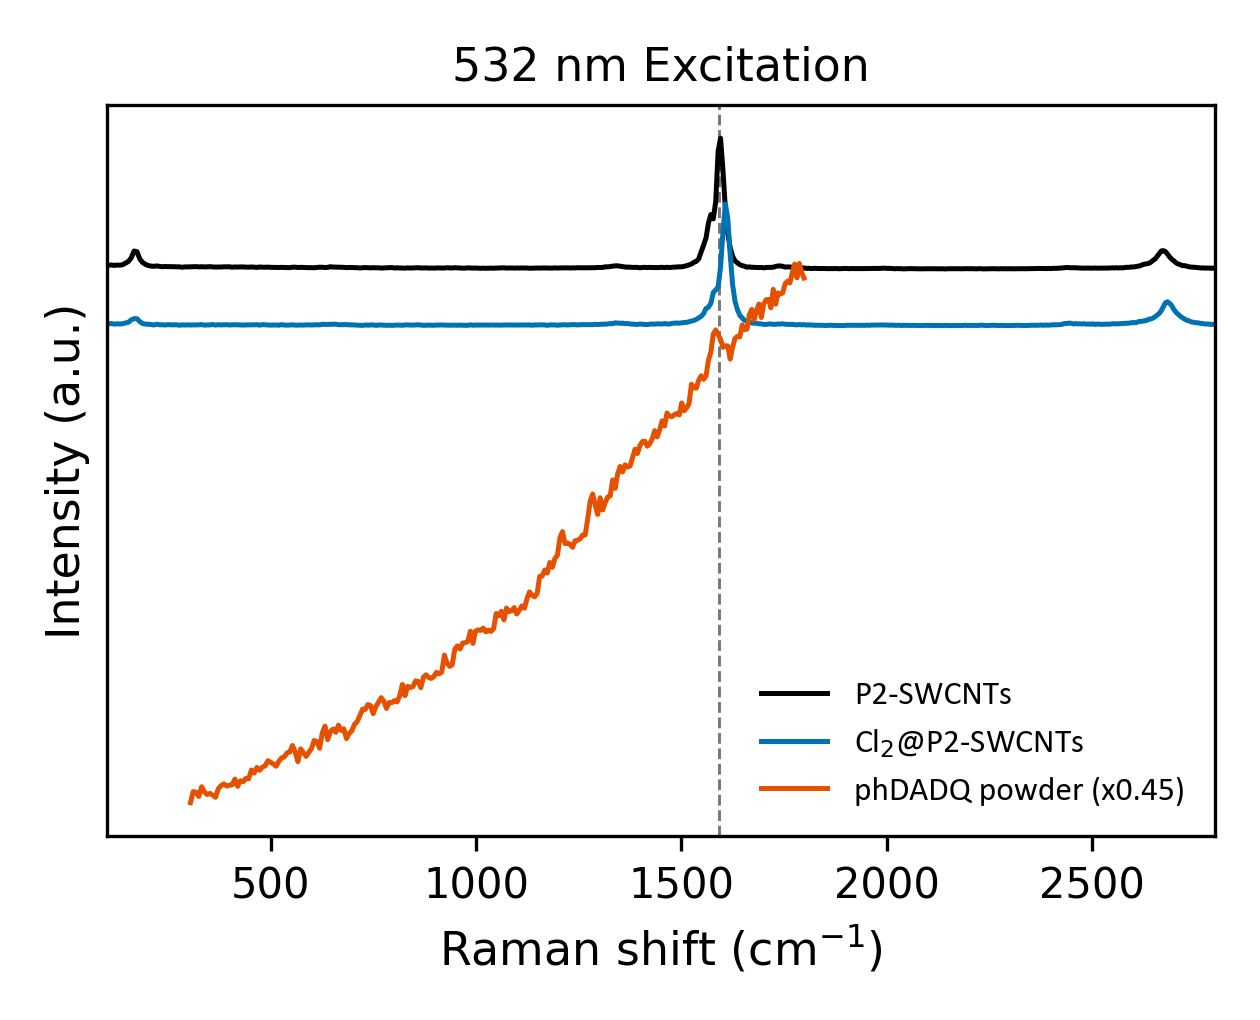

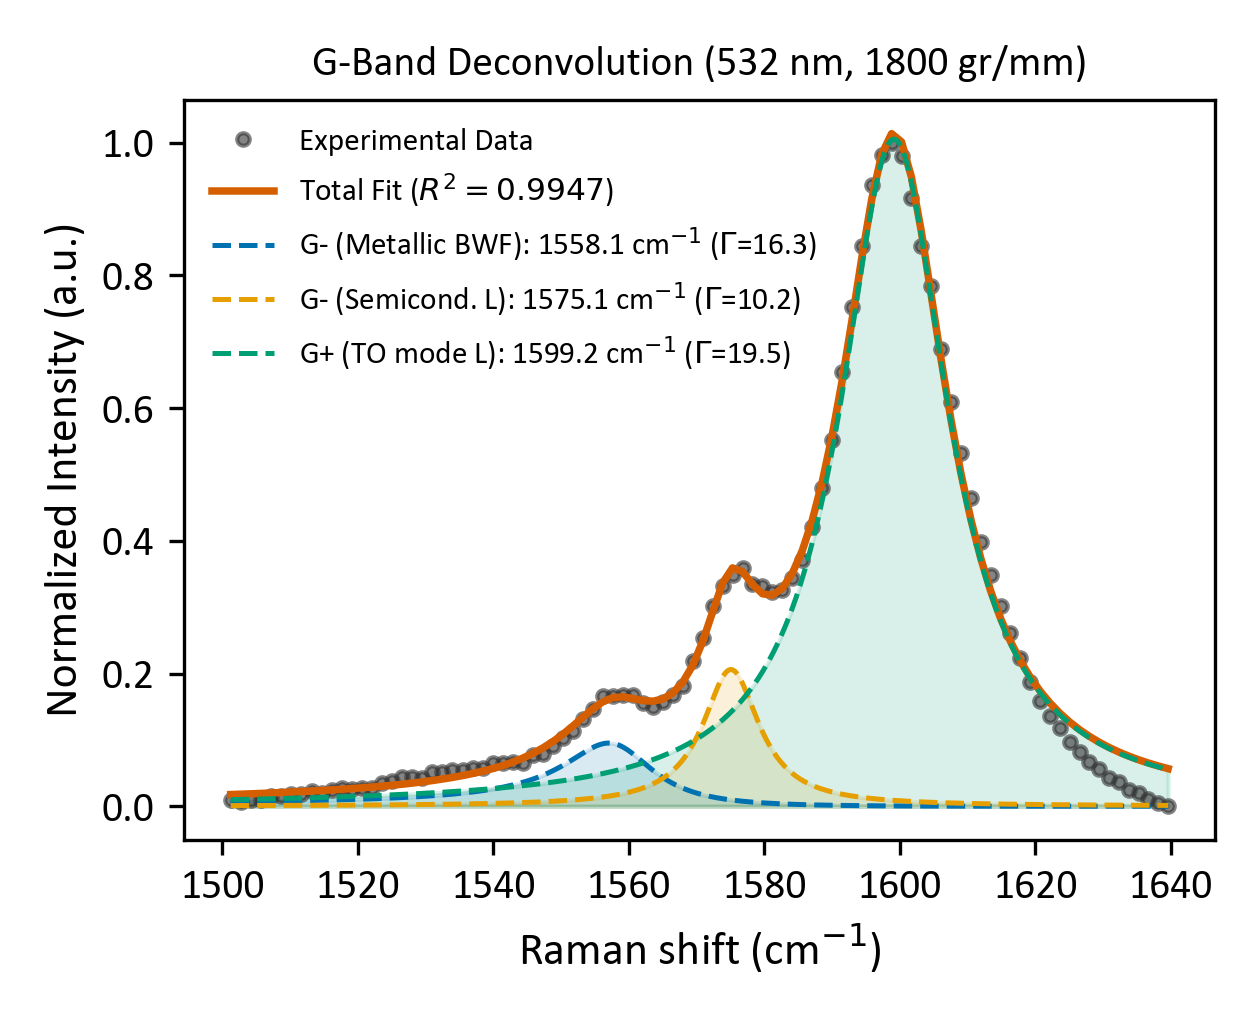

,Peak,Type,Center (cm-1),Center_Err,FWHM (cm-1),FWHM_Err,Amplitude,Area,1/q (BWF)
0,G- (Metallic BWF),BWF,1558.09,1.42,16.34,4.21,0.094,2.32,-0.127
1,G- (Semicond. L),L,1575.07,0.36,10.19,1.46,0.206,3.15,NaN
2,G+ (TO mode L),L,1599.15,0.10,19.52,0.31,1.006,27.54,NaN


,Sample,Laser,RBM (cm-1),d_t (nm),G+ Pos (cm-1),ΔG Shift (cm-1),D Pos (cm-1),I_D / I_G (Height),A_D / A_G (Area),2D Pos (cm-1),I_2D / I_G
0,P2-SWCNTs,532 nm,166.9,1.51,1595.46,0.00,1338.7,0.015,0.020,2674.2,0.168
1,Cl$_2$@P2-SWCNTs,532 nm,173.8,1.44,1607.22,11.76,1338.7,0.038,-0.029,2684.5,0.672
2,phDADQ powder (x0.45),532 nm,160.0,1.58,1583.69,-11.77,1284.0,0.363,-0.255,2684.5,0.554


In [ ]:
# ==============================================================================
# [ CELL 6 ] : WORKSPACE EXAMPLES (PLOT, OVERLAY MOLECULE, FIT G/2D & METRICS)
# ==============================================================================

# ------------------------------------------------------------------------------
# EXAMPLE 1: Plotting Pristine SWCNTs vs Encapsulated + Rescaled Free Molecule
# ------------------------------------------------------------------------------
# Tuple format: (Filename_or_Object, Label, Color, Linestyle, Manual_Scale, Optional_Trim_Tuple)
config_532_comparison = [
    # 1. Pristine reference (Normalized to G-band = 1.0, scale = 1.0)
    ('260911_P2_532 nm_600gr_x50 LD_0_1%_3_20_100_100_sc2700_1.txt', 'P2-SWCNTs', '#000000', '-', 1.0, None),
    
    # 2. Encapsulated sample (Normalized to G-band = 1.0, scale = 1.0)
    ('260911_Cl2@P2_532 nm_600gr_x50 LD_0_1%_3_20_100_100_sc2700_1.txt', 'Cl$_2$@P2-SWCNTs', '#0072B2', '-', 1.0, None),
    
    # 3. Free Molecule (phDADQ): Rescaled freely by hand (e.g., 0.45) and trimmed to [300, 1800] cm-1
    ('260911_phDADQ_powder_532 nm_600gr_x50 LD_0_1%_3_3_100_100_sc2700.txt', 'phDADQ powder (x0.45)', '#E65100', '-', 0.45, (300, 1800)),
]

PlotRamanConfig(
    config=config_532_comparison,
    spectra_dict=raman_spectra,
    offset_step=-0.6,
    xmin=100, xmax=2800,
    norm_xmin=1550, norm_xmax=1620, norm_mode="M",  # Normalize all to G-band maximum
    vlines=[1592],                                  # Vertical guide on pristine G+ peak
    hide_yticks=True,
    title="532 nm Excitation"
)


# ------------------------------------------------------------------------------
# EXAMPLE 2: Multi-Lorentzian / BWF Fitting of the SWCNT G-Band (1500 - 1650 cm-1)
# ------------------------------------------------------------------------------
# Define peak constraints: (initial_guess, min_bound, max_bound)
g_band_peaks = [
    {"name": "G- (Metallic BWF)", "type": "BWF", "x0": (1545, 1525, 1560), "fwhm": (35, 10, 80), "q_inv": (-0.12, -0.4, 0.0)},
    {"name": "G- (Semicond. L)",  "type": "L",   "x0": (1570, 1560, 1582), "fwhm": (16, 5, 35)},
    {"name": "G+ (TO mode L)",    "type": "L",   "x0": (1592, 1585, 1605), "fwhm": (14, 5, 30)},
]

fit_results_G = FitRamanBand(
    spec_source='260911_Cl2@P2_532 nm_1800gr_x50 LD_1%_3_10_100_100_sc875.txt',
    spectra_dict=raman_spectra,
    fit_window=(1500, 1640),
    peak_guesses=g_band_peaks,
    title="G-Band Deconvolution (532 nm, 1800 gr/mm)"
)


# ------------------------------------------------------------------------------
# EXAMPLE 3: Multi-Lorentzian Fitting of the 2D (G') Band (2550 - 2780 cm-1)
# ------------------------------------------------------------------------------
twoD_band_peaks = [
    {"name": "2D_low",  "type": "L", "x0": (2665, 2630, 2685), "fwhm": (35, 10, 70)},
    {"name": "2D_high", "type": "L", "x0": (2690, 2675, 2720), "fwhm": (30, 10, 70)},
]

# Uncomment to run when viewing a spectrum covering up to 2800 cm-1:
# fit_results_2D = FitRamanBand(
#     spec_source='260911_Cl2@P2_532 nm_600gr_x50 LD_0_1%_3_20_100_100_sc2700_1.txt',
#     spectra_dict=raman_spectra,
#     fit_window=(2550, 2780),
#     peak_guesses=twoD_band_peaks,
#     title="2D-Band Fit"
# )


# ------------------------------------------------------------------------------
# EXAMPLE 4: Automated Doping & Defect Table (G-Shift, ID/IG, RBM Diameter)
# ------------------------------------------------------------------------------
metrics_df = AnalyzeSWCNTMetrics(config=config_532_comparison, spectra_dict=raman_spectra)